# EDA — Diabetes Prediction Dataset

Khám phá dữ liệu cho nhánh **DB → ML/DL** của hệ multi-agent. Notebook chạy từ thư mục `src/Project`.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "ml":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from config import DATA_PATH, FIGURES_DIR
from ml.preprocess import load_clean
import nbstyle
nbstyle.install()           # bảng có màu cố định, đọc rõ ở cả giao diện sáng lẫn tối

raw = pd.read_csv(DATA_PATH)
df, stats = load_clean()
print(raw.shape)
stats

(100000, 9)


{'rows_raw': 100000,
 'duplicates': 3854,
 'gender_other': 18,
 'rows_clean': 96128,
 'positive_rate': 0.08823651797603196}

## 1. Chất lượng dữ liệu
Dòng trùng hoàn toàn, giá trị `No Info` và `Other`.

In [2]:
quality = pd.DataFrame({
    "chỉ số": ["Số dòng gốc", "Dòng trùng hoàn toàn", "gender = Other", "smoking_history = No Info", "Số dòng sau làm sạch"],
    "giá trị": [len(raw), raw.duplicated().sum(), (raw.gender == "Other").sum(),
                (raw.smoking_history == "No Info").sum(), len(df)],
})
quality

chỉ số,giá trị
Số dòng gốc,100 000
Dòng trùng hoàn toàn,3854
gender = Other,18
smoking_history = No Info,35 816
Số dòng sau làm sạch,96 128


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,96 128,41.80,22.46,0.08,24.0,43.00,59.00,80.00
hypertension,96 128,0.08,0.27,0.00,0.0,0.00,0.00,1.00
heart_disease,96 128,0.04,0.20,0.00,0.0,0.00,0.00,1.00
bmi,96 128,27.32,6.77,10.01,23.4,27.32,29.86,95.69
HbA1c_level,96 128,5.53,1.07,3.50,4.8,5.80,6.20,9.00
blood_glucose_level,96 128,138.22,40.91,80.00,100.0,140.00,159.00,300.00
diabetes,96 128,0.09,0.28,0.00,0.0,0.00,0.00,1.00


## 2. Mất cân bằng nhãn

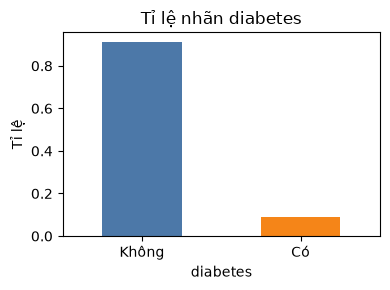

,proportion
diabetes,
Không,0.9118
Có,0.0882


In [4]:
rate = df["diabetes"].value_counts(normalize=True).rename({0: "Không", 1: "Có"})
ax = rate.plot.bar(color=["#4C78A8", "#F58518"], figsize=(4, 3), rot=0, title="Tỉ lệ nhãn diabetes")
ax.set_ylabel("Tỉ lệ")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_label_balance.png", dpi=150); plt.show()
rate.round(4)

## 3. Phân phối đặc trưng số theo nhãn

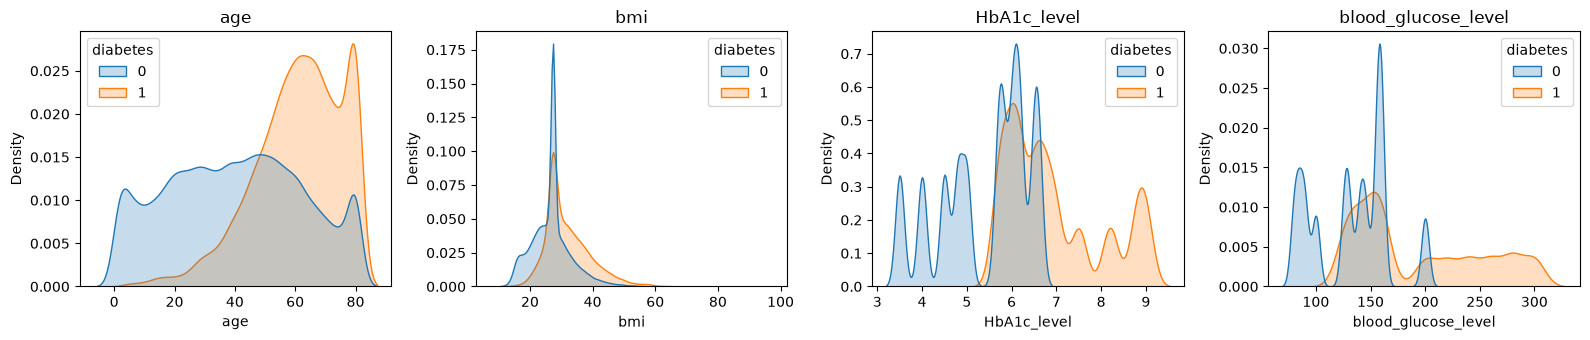

In [5]:
cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, cols):
    sns.kdeplot(data=df, x=col, hue="diabetes", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_numeric_kde.png", dpi=150); plt.show()

## 4. Tỉ lệ mắc theo đặc trưng phân loại

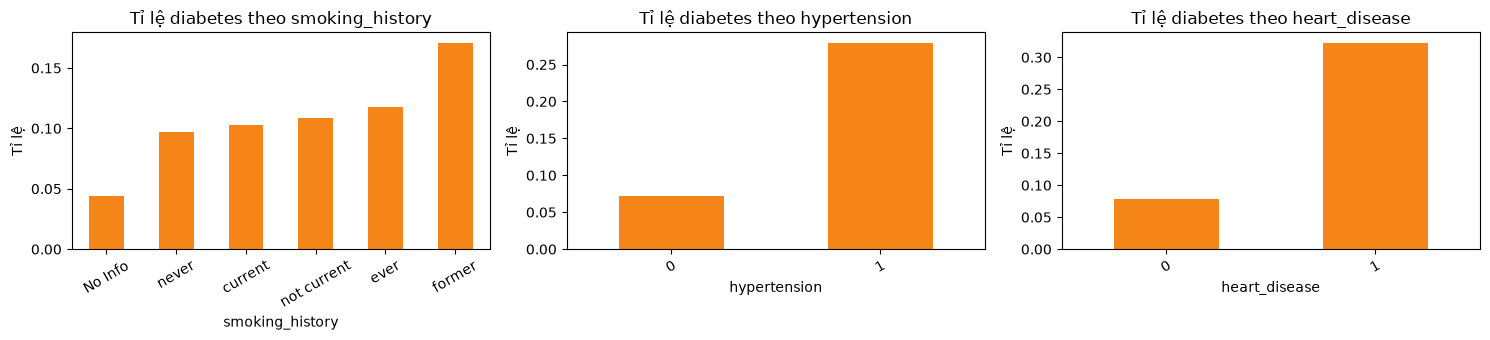

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["smoking_history", "hypertension", "heart_disease"]):
    df.groupby(col)["diabetes"].mean().sort_values().plot.bar(ax=ax, color="#F58518", rot=30)
    ax.set_title(f"Tỉ lệ diabetes theo {col}"); ax.set_ylabel("Tỉ lệ")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_categorical_rates.png", dpi=150); plt.show()

## 5. HbA1c và đường huyết gần như quyết định nhãn
Đây là lý do mô hình *full* đạt điểm rất cao và cần thêm mô hình *screening* không dùng xét nghiệm.

In [7]:
bins = {"HbA1c_level": [3, 5.7, 6.5, 7, 10], "blood_glucose_level": [0, 140, 200, 250, 400]}
for col, edges in bins.items():
    table = df.groupby(pd.cut(df[col], edges, right=False), observed=True)["diabetes"].agg(["count", "mean"])
    print(col); print(table.round(3), end="\n\n")
both = df[(df.HbA1c_level >= 6.6) | (df.blood_glucose_level >= 200)]
print(f"HbA1c ≥ 6,6% hoặc glucose ≥ 200: {len(both)} ca, tỉ lệ diabetes = {both.diabetes.mean():.3f}")

HbA1c_level
             count   mean
HbA1c_level              
[3.0, 5.7)   36258  0.000
[5.7, 6.5)   39770  0.083
[6.5, 7.0)   16854  0.115
[7.0, 10.0)   3246  1.000

blood_glucose_level
                     count   mean
blood_glucose_level              
[0, 140)             41900  0.032
[140, 200)           43675  0.074
[200, 250)            8522  0.221
[250, 400)            2031  1.000

HbA1c ≥ 6,6% hoặc glucose ≥ 200: 19908 ca, tỉ lệ diabetes = 0.320


## 6. Tương quan

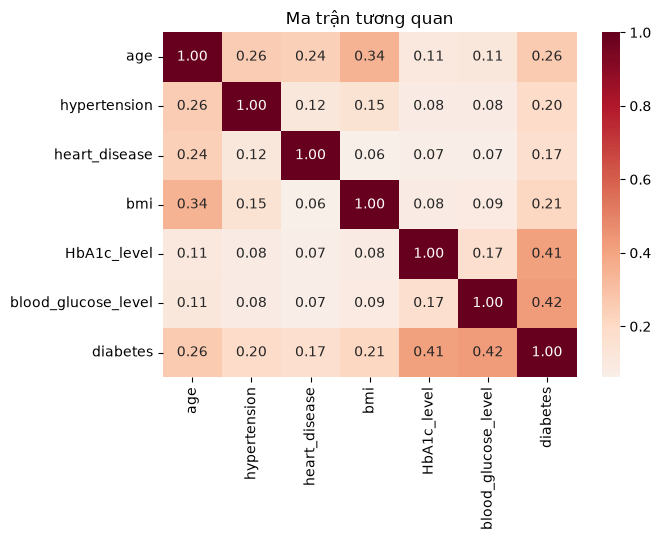

In [8]:
num = df[["age", "hypertension", "heart_disease", "bmi", "HbA1c_level", "blood_glucose_level", "diabetes"]]
plt.figure(figsize=(7, 5.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Ma trận tương quan"); plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_correlation.png", dpi=150); plt.show()